# ARTI5001 Assignment 2 - FFHQ128 Variational Autoencoder

**Student name:**  Wimukthi Rajapaksha  
**Student ID:**  a1988198

Submit this notebook as `<student_id>_<name>_A2.ipynb` after restarting the
kernel and running all cells in order. Keep all required outputs visible.

This notebook provides data-loading infrastructure and evidence headings. It
does not prescribe the assessed model, loss, training loop, or analysis.


## Assessment conditions

- Implement the convolutional VAE, reparameterisation, analytic KL, objective,
  and training/evaluation logic yourself.
- Train the fixed baseline and exactly one approved controlled variant.
- Use the public rubric supplied with the assignment.
- Checkpoint saving is optional and ungraded.
- Complete the mandatory source and AI-use declaration at the end.
- Do not upload FFHQ images or protected course material to external AI tools.


## 1. Reproducible setup and data checks

Configure the experiment in one place. Both runs must use the same seed, split,
batch size, optimiser, learning rate, epoch count, and evaluation procedure.


**Data preparation and provenance.**

- **Source:** the official NVIDIA FFHQ release (Karras et al., 2019), `thumbnails128x128` folder (aligned 128 x 128 RGB PNG thumbnails, 70,000 images plus NVIDIA's `LICENSE.txt`), downloaded from the official Google Drive folder linked in the assignment brief. The dataset is licensed by NVIDIA under CC BY-NC-SA 4.0, and the individual images under the Flickr licences listed in `LICENSE.txt`. It is used here only for this non-commercial educational task.
- **Subset:** only the 40,000 images listed in `ffhq128_split_manifest.csv` are used (30,000 train / 5,000 validation / 5,000 test, checked in the next cells). The supplied loading cell is unmodified.
- **Layout:** the manifest expects 1,000-image subfolders (`images/01000/01234.png`, folder = `image_id // 1000 * 1000`), but the official download arrived as one flat folder (`thumbnails128x128/01234.png`). The code cell after the configuration cell prepares this layout automatically: if all 40,000 manifest images are already under `ffhq128/images/` it changes nothing; otherwise it links them from `thumbnails128x128/` with symbolic links (copies where links are not permitted), so no image is copied, resized or altered, and it places the manifest at the expected path. If the images are already in 1,000-image subfolders, put them directly under `ffhq128/images/`.

In [1]:
from pathlib import Path
import copy
import math
import random
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid

# ===================== EXPERIMENT CONFIGURATION =====================
DATA_ROOT = Path("./ffhq128")
MANIFEST_PATH = DATA_ROOT / "ffhq128_split_manifest.csv"
IMAGE_ROOT = DATA_ROOT / "images"

# ===================== SHARED CONTROLS - IDENTICAL FOR BASELINE AND VARIANT =====================
SEED = 5001
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS = 15
BASELINE_LATENT_DIM = 16
BASELINE_BETA = 1.0

# A Dataset class defined in a notebook cannot be pickled into spawned worker processes
# (macOS/ Windows), so worker processes are only used on Linux (e.g. Colab).
NUM_WORKERS = 2 if sys.platform.startswith("linux") else 0
OPTIMISER_NAME = "Adam"
ADAM_BETAS = (0.9, 0.999)
LOGVAR_CLAMP = (-10.0, 10.0)  # numerical-stability guard on log-variance
EVAL_SEED = 7 # fixes posterior noise during val/ test evaluation
GEN_SEED = 2026 # fixes test-image choice, prior noise, interpolation endpoints
NUM_RECON_IMAGES = 12
NUM_PRIOR_SAMPLES = 64
NUM_INTERP_STEPS = 12
WARMUP_FRACTION = 0.30 # only used if the variant is the KL warm-up



# controlled variant: EXACTLY ONE factor differs from the baseline
# approved options (set these three values accordingly):
#   latent capacity        : VARIANT_LATENT_DIM=32, VARIANT_BETA=1.0,         VARIANT_BETA_SCHEDULE="fixed"
#   KL weight              : VARIANT_LATENT_DIM=16, VARIANT_BETA=0.25 or 2.0, VARIANT_BETA_SCHEDULE="fixed"
#   KL warm-up             : VARIANT_LATENT_DIM=16, VARIANT_BETA=1.0,         VARIANT_BETA_SCHEDULE="warmup"
VARIANT_LATENT_DIM = 16
VARIANT_BETA = 0.25
VARIANT_BETA_SCHEDULE = "fixed"

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps") # apple silicon GPU
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)

warnings.filterwarnings("ignore", message=".*pin_memory.*") # pin_memory is a no-op off CUDA

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__)

Device: mps
torch 2.5.1


In [2]:
# ===================== DATA LAYOUT PREPARATION (run once, before the supplied loading cell) =====================
# the supplied loader expects ./ffhq128/ffhq128_split_manifest.csv and ./ffhq128/images/<folder>/<id>.png,
# where folder = image_id // 1000 * 1000. If the official thumbnails were downloaded as one flat folder 
# (thumbnails128x128/01234.png), this cell links them into that layout; if the layout is already 
# complete it changes nothing. Images are never modified.

import os
import shutil

FLAT_SOURCE = Path("./thumbnails128x128")
MANIFEST_SOURCES = [Path("./ffhq128/ffhq128_split_manifest.csv"), Path("./ffhq128_split_manifest.csv")]


def prepare_data_layout():
    if not MANIFEST_PATH.exists():
        source = next((p for p in MANIFEST_SOURCES if p.exists()), None)
        if source is None:
            raise FileNotFoundError(f"Course manifest not found; place it at {MANIFEST_PATH}")
        DATA_ROOT.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(source, MANIFEST_PATH)
    filenames = pd.read_csv(MANIFEST_PATH)["filename"]
    missing = [f for f in filenames if not (IMAGE_ROOT/f).is_file()]
    if not missing:
        return f"Data layout OK: all {len(filenames)} manifest images found under {IMAGE_ROOT} (Nothing changed)."
    if not FLAT_SOURCE.is_dir():
        raise FileNotFoundError(f"{len(missing)} manifest images missing under {IMAGE_ROOT}, "
                                f"and no flat download found at {FLAT_SOURCE}")

    linked = copied = 0
    for f in missing:
        src, dst = (FLAT_SOURCE / Path(f).name).resolve(), IMAGE_ROOT/f
        if not src.is_file():
            raise FileNotFoundError(f"{src} (listed in the manifest) is not in {FLAT_SOURCE}")
        dst.parent.mkdir(parents=True, exist_ok=True)
        if dst.is_symlink(): # stale link from an earlier, moved download
            dst.unlink()
        try:
            os.symlink(src, dst)
            linked+=1
        except OSError: # windows without symlink permission
            shutil.copyfile(src,dst)
            copied+=1
    return f"Prepared data layout from {FLAT_SOURCE}: {linked} symlinks, {copied} copies (images unmodified)."


print(prepare_data_layout())

Prepared data layout from thumbnails128x128: 40000 symlinks, 0 copies (images unmodified).


In [3]:
# Supplied infrastructure: do not modify this cell.
class ManifestFFHQ128(Dataset):
    def __init__(self, image_root, manifest_path, split):
        table = pd.read_csv(manifest_path)
        required = {"image_id", "filename", "split"}
        if not required.issubset(table.columns):
            raise ValueError(f"Manifest must contain {sorted(required)}")
        self.rows = table.loc[table["split"] == split].reset_index(drop=True)
        self.image_root = Path(image_root)
        self.to_tensor = ToTensor()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        path = self.image_root / row["filename"]
        with Image.open(path) as image:
            tensor = self.to_tensor(image.convert("RGB"))
        return tensor, int(row["image_id"])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_loaders():
    datasets = {
        split: ManifestFFHQ128(IMAGE_ROOT, MANIFEST_PATH, split)
        for split in ("train", "val", "test")
    }
    generator = torch.Generator().manual_seed(SEED)
    loaders = {
        "train": DataLoader(datasets["train"], batch_size=BATCH_SIZE,
                            shuffle=True, generator=generator,
                            num_workers=NUM_WORKERS, pin_memory=True),
        "val": DataLoader(datasets["val"], batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS,
                          pin_memory=True),
        "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=NUM_WORKERS,
                           pin_memory=True),
    }
    return datasets, loaders


set_seed(SEED)
datasets, loaders = make_loaders()


In [4]:
# Show split sizes, batch shape/range, sample images, and any other
# checks needed to make the pipeline and experiment auditable.


# ===================== CONFIGURATION RECORD AND SINGLE-FACTOR CHECK =====================
BASELINE_CONFIG = dict(name="Baseline", latent_dim=BASELINE_LATENT_DIM, beta=BASELINE_BETA, beta_schedule="fixed")
VARIANT_CONFIG = dict(name=f"Variant (latent={VARIANT_LATENT_DIM}, beta={VARIANT_BETA}, {VARIANT_BETA_SCHEDULE})",
                      latent_dim=VARIANT_LATENT_DIM, beta=VARIANT_BETA, beta_schedule=VARIANT_BETA_SCHEDULE)

APPROVED_VARIANTS = [
    dict(latent_dim=32, beta=1.0, beta_schedule="fixed"),
    dict(latent_dim=16, beta=0.25, beta_schedule="fixed"),
    dict(latent_dim=16, beta=2.0, beta_schedule="fixed"),
    dict(latent_dim=16, beta=1.0, beta_schedule="warmup"),
]

factor_keys = ("latent_dim", "beta", "beta_schedule")
assert {k: VARIANT_CONFIG[k] for k in factor_keys} in APPROVED_VARIANTS, "Variant is not an approved option"
changed = [k for k in factor_keys if BASELINE_CONFIG[k] != VARIANT_CONFIG[k]]
assert len(changed) == 1, f"Exactly one factor must change, got {changed}"

shared_controls = pd.DataFrame({
    "setting": ["seed", "device", "batch size", "optimiser", "learning rate", "Adam betas", 
                "epochs", "data split", "augmentation", "logvar clamp", "eval seed", "generation seed"],
    "value (both runs)": [SEED, str(DEVICE), BATCH_SIZE, OPTIMISER_NAME, LEARNING_RATE, ADAM_BETAS,
                          EPOCHS, "ffhq128_split_manifest.csv", "none", LOGVAR_CLAMP, EVAL_SEED, GEN_SEED],
})

display(shared_controls)
display(pd.DataFrame([BASELINE_CONFIG, VARIANT_CONFIG]).set_index("name"))
print("Single changed factor:", changed[0])

,setting,value (both runs)
0,seed,5001
1,device,mps
2,batch size,64
3,optimiser,Adam
4,learning rate,0.001
5,Adam betas,"(0.9, 0.999)"
6,epochs,15
7,data split,ffhq128_split_manifest.csv
8,augmentation,none
9,logvar clamp,"(-10.0, 10.0)"


,latent_dim,beta,beta_schedule
name,,,
Baseline,16,1.00,fixed
"Variant (latent=16, beta=0.25, fixed)",16,0.25,fixed


Single changed factor: beta


,split,observed,expected
0,train,30000,30000
1,val,5000,5000
2,test,5000,5000


Splits are disjoint; missing image files: 0
Batch shape: (64, 3, 128, 128) | dtype: torch.float32
Pixel range: min=0.0000, max=1.0000
Steps per training epoch: 469


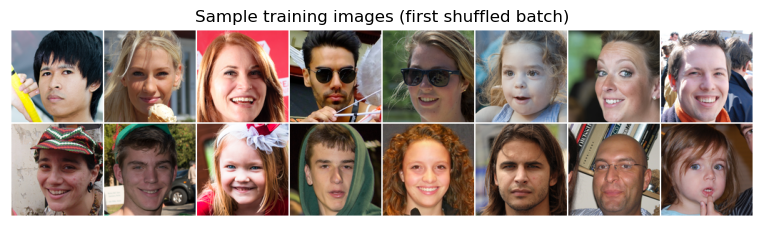

In [5]:
# ===================== SPLIT SIZES, DISJOINTNESS AND FILE CHECKS =====================
manifest = pd.read_csv(MANIFEST_PATH)
expected_sizes = {"train": 30000, "val": 5000, "test": 5000}
size_table = pd.DataFrame({
    "split": list(expected_sizes),
    "observed": [len(datasets[s]) for s in expected_sizes],
    "expected": list(expected_sizes.values())
})

display(size_table)
for s, n in expected_sizes.items():
    assert len(datasets[s])==n, f"{s} split has {len(datasets[s])} images, expected {n}"


split_ids = {s: set(datasets[s].rows["image_id"]) for s in expected_sizes}
assert split_ids["train"].isdisjoint(split_ids["val"])
assert split_ids["train"].isdisjoint(split_ids["test"])
assert split_ids["val"].isdisjoint(split_ids["test"])

missing = [f for f in manifest["filename"] if not (IMAGE_ROOT / f).exists()]

print(f"Splits are disjoint; missing image files: {len(missing)}")

assert not missing, missing[:5]


# ===================== BATCH SHAPE / RANGE CHECK =====================
# NOTE: drawing a batch advances the train shuffle generator, so the loaders are
# recreated (with set_seed) immediately before each training run

x_check, id_check = next(iter(loaders["train"]))
print("Batch shape:", tuple(x_check.shape), "| dtype:", x_check.dtype)
print(f"Pixel range: min={x_check.min().item():.4f}, max={x_check.max().item():.4f}")

assert x_check.shape == (BATCH_SIZE, 3, 128, 128)
assert x_check.min() >= 0.0 and x_check.max() <= 1.0

print("Steps per training epoch:", len(loaders["train"]))

# ===================== SAMPLE IMAGES =====================
def show_grid(images, nrow, title, ax=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    if ax is None:
        _, ax = plt.subplots(figsize=(nrow*1.2, (len(images)//nrow)*1.2+0.5))
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")
    return ax

show_grid(x_check[:16], nrow=8, title="Sample training images (first shuffled batch)")
plt.show()


## 2. Convolutional VAE architecture

Implement a convolutional encoder and decoder for `3 x 128 x 128` images. The
forward pass must return the reconstruction or logits, `mu`, and `logvar`.
Record the trainable-parameter count and keep it at or below 10 million.

Explain tensor shapes and key architecture decisions in markdown near the code.


**Architecture and tensor shapes** (`B` = batch size, `d` = latent dimension)

|Stage|Operation|Output shape|
|---|---|---|
|Input | RGB image in [0, 1] | `B x 3 x 128 x 128` |
|Encoder 1-5 | Conv 4x4, stride 2, pad 1 -> BatchNorm -> LeakyReLU(0.2); channels 32, 64, 128, 256, 256 | `Bx32x64x64` -> `Bx64x32x32` -> `Bx128x16x16` -> `Bx256x8x8` -> `Bx256x4x4`|
|Flatten| - | `B x 4096` |
|Heads | two separate Linear layers | `mu: B x d`, `logvar: B x d` (clamped to [-10, 10]) |
|Reparameterise | `z = mu + exp(0.5·logvar) · ε`, `ε ~ N(0, I)` | `B x d`|
|Decoder input | Linear -> ReLU -> reshape | `B x 256 x 4 x 4`|
|Decoder 1-5|Nearest x2 upsample -> Conv 3x3 -> BatchNorm -> LeakyReLU(0.2); channels 256, 128, 64, 32, 32 | `Bx256x8x8` -> ... -> `Bx32x128x128` | 
|Output | Conv 3x3 to 3 channels, **no activation (logits)** | `B x 3 x 128 x 128`|

Key decisions: five stride-2 stages reduce 128x128 to a 4x4 map; each bottleneck feature has a 94x94-pixel receptive field, and the linear heads combine all 16 positions, so `mu` and `logvar` depend on the whole aligned face.
Strided convolutions (rather than pooling) let the encoder learn its own downsampling. In the decoder, nearest-neighbour upsampling followed by a 3x3 convolution is used instead of transposed convolutions to avoid checkerboard artefacts on smooth skin regions. 

The decoder returns logits, which are paired with `binary_cross_entropy_with_logits` (Section 3); `torch.sigmoid` is applied only for visualisation.
The latent size only changes the two heads and the first decoder Linear, so the same class serves both runs.

In [6]:
# Implement your convolutional VAE here.

def encoder_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2, inplace=True),
    )

def decoder_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Upsample(scale_factor=2, mode="nearest"),
        nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2, inplace=True),
    )

class ConvVAE(nn.Module):
    def __init__(self, latent_dim, enc_channels=(32, 64, 128, 256, 256),
                 dec_channels=(256, 128, 64, 32, 32), logvar_clamp=LOGVAR_CLAMP):
        super().__init__()
        self.latent_dim = latent_dim
        self.logvar_clamp = logvar_clamp
        self.bottleneck_shape = (enc_channels[-1], 4, 4) # 128 / 2**5 = 4
        flat = int(np.prod(self.bottleneck_shape)) # 4096

        layers, in_ch = [], 3
        for ch in enc_channels:
            layers.append(encoder_block(in_ch, ch))
            in_ch = ch

        self.encoder = nn.Sequential(*layers)
        self.fc_mu = nn.Linear(flat, latent_dim)
        self.fc_logvar = nn.Linear(flat, latent_dim)

        self.fc_decode = nn.Linear(latent_dim, flat)
        layers, in_ch = [], enc_channels[-1]
        for ch in dec_channels:
            layers.append(decoder_block(in_ch, ch))
            in_ch = ch

        self.decoder = nn.Sequential(*layers)
        self.to_logits = nn.Conv2d(in_ch, 3, kernel_size=3, padding=1)

    def encode(self, x):
        h = self.encoder(x).flatten(start_dim=1)              # B x 4096
        mu = self.fc_mu(h)                                    # B x d
        logvar = self.fc_logvar(h).clamp(*self.logvar_clamp)  # B x d
        return mu, logvar

    @staticmethod
    def reparameterise(mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)     # standard normal noise
        return mu+eps*std

    def decode(self, z):
        h = F.relu(self.fc_decode(z)).view(-1, *self.bottleneck_shape)
        return self.to_logits(self.decoder(h))   # B x 3 x 128 x 128 logits


    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterise(mu, logvar)
        logits = self.decode(z)
        return logits, mu, logvar


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
        

In [7]:
# Instantiate a baseline model and display shape and parameter-count checks.
PARAM_BUDGET = 10_000_000
param_rows = []
for cfg in (BASELINE_CONFIG, VARIANT_CONFIG):
    m = ConvVAE(cfg["latent_dim"])
    n_params = count_trainable_parameters(m)
    param_rows.append({"model": cfg["name"],
                        "latent_dim": cfg["latent_dim"],
                        "trainable parameters": n_params,
                        "within 10M budget": n_params <= PARAM_BUDGET})
    assert n_params <= PARAM_BUDGET

display(pd.DataFrame(param_rows))


# shape trace through the baseline model
probe = ConvVAE(BASELINE_LATENT_DIM).to(DEVICE).eval()
with torch.no_grad():
    h=x_check[:4].to(DEVICE)
    print(f"{'input':<22}{tuple(h.shape)}")
    for i, block in enumerate(probe.encoder):
        h=block(h)
        print(f"{'encoder block ' + str(i+1):<22}{tuple(h.shape)}")
    logits, mu, logvar = probe(x_check[:4].to(DEVICE))
    print(f"{'mu/logvar':<22}{tuple(mu.shape)}/{tuple(logvar.shape)}")
    h=F.relu(probe.fc_decode(mu)).view(-1, *probe.bottleneck_shape)
    print(f"{'decoder input':<22}{tuple(h.shape)}")
    for i, block in enumerate(probe.decoder):
        h=block(h)
        print(f"{'decoder block '+str(i+1):<22}{tuple(h.shape)}")
    print(f"{'logits':<22}{tuple(logits.shape)}")
assert logits.shape == (4, 3, 128, 128)
assert mu.shape == logvar.shape == (4, BASELINE_LATENT_DIM)
del probe


,model,latent_dim,trainable parameters,within 10M budget
0,Baseline,16,2928451,True
1,"Variant (latent=16, beta=0.25, fixed)",16,2928451,True


input                 (4, 3, 128, 128)
encoder block 1       (4, 32, 64, 64)
encoder block 2       (4, 64, 32, 32)
encoder block 3       (4, 128, 16, 16)
encoder block 4       (4, 256, 8, 8)
encoder block 5       (4, 256, 4, 4)
mu/logvar             (4, 16)/(4, 16)
decoder input         (4, 256, 4, 4)
decoder block 1       (4, 256, 8, 8)
decoder block 2       (4, 128, 16, 16)
decoder block 3       (4, 64, 32, 32)
decoder block 4       (4, 32, 64, 64)
decoder block 5       (4, 32, 128, 128)
logits                (4, 3, 128, 128)


## 3. VAE objective and verification

Implement a reconstruction term, analytic diagonal-Gaussian KL against
`N(0,I)`, and `reconstruction + beta * KL`. Use and document a coherent
per-image reduction. Report unweighted KL separately.


**Objective and reduction.** For one image $x$ with $D=3 \cdot 128 \cdot 128 = 49{,}152$ values:

- Reconstruction: $\mathcal{L}_{rec}(x) = \sum_{i=1}^{D} \mathrm{BCE}(\text{logit}_i, x_i)$, computed with `binary_cross_entropy_with_logits` (log-sum-exp stable), **summed over pixels and channels**
- KL (analytic, diagonal Gaussian vs. $\mathcal{N}(0, I)$): $\mathrm{KL}(x) = \tfrac{1}{2}\sum_{j=1}^{d}\left(\mu_j^2 + \sigma_j^2 - 1 - \log\sigma_j^2\right)$, **summed over latent dimensions**
- Total: $\mathcal{L}(x) = \mathcal{L}_{rec}(x) + \beta \cdot \mathrm{KL}(x)$

All three are reported as the **mean over images** (nats per image). Summing within an image keeps the two terms on the same per-image scale, so `beta = 1` corresponds to the negative ELBO; the KL is always reported unweighted. Targets stay in [0, 1], so they are valid BCE targets for sigmoid-logit outputs. Because BCE on continuous targets is not a normalised likelihood, its minimum is not zero (it equals the pixel entropy), so reconstruction values are compared between models rather than read as absolute quality.

In [8]:
# Implement the reconstruction term, KL term, and total objective here.
def reconstruction_loss(logits, x):
    # per-image BCE summed over 3 x 128 x 128 values -> shape (B,)
    per_value = F.binary_cross_entropy_with_logits(logits, x, reduction="none")
    return per_value.flatten(start_dim=1).sum(dim=1)

def reconstruction_floor(x):
    # per-image BCE of a perfect reconstruction (the binary entropy of the targets) -> shape (B,).
    # BCE on continuous targets can't go below this, so "excess" = recon - floor is the model's own error.
    p = x.clamp(1e-6, 1 - 1e-6)
    return -(x*p.log() + (1-x)*(1-p).log()).flatten(start_dim=1).sum(dim=1)

def kl_divergence(mu, logvar):
    # analytic KL( N(mu, diag(exp(logvar))) || N(0, I) ) summed over latent dims -> shape(B,)
    return 0.5 * torch.sum(mu.pow(2) + logvar.exp() - 1.0 - logvar, dim=1)
    
def kl_per_dimension(mu, logvar):
    # same quantity without the sum over dimensions -> shape (B, d); used for active-unit diagnostics
    return 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar)

def vae_objective(logits, x, mu, logvar, beta):
    # returns per-image tensors; callers take .mean() for the batch loss
    recon = reconstruction_loss(logits, x)
    kl = kl_divergence(mu, logvar)
    total = recon+beta*kl
    return {"total": total, "recon": recon, "kl": kl}

def beta_at_step(step, total_steps, cfg):
    # fixed beta or linear warm-up 0 -> cfg["beta"] over the first WARMUP_FRACTION of optimiser steps
    if cfg["beta_schedule"] == "fixed":
        return float(cfg["beta"])
    if cfg["beta_schedule"] == "warmup":
        warmup_steps = WARMUP_FRACTION * total_steps
        return float(cfg["beta"])*min(1.0, step/warmup_steps)
    raise ValueError(cfg["beta_schedule"])

In [9]:
# Run shape, finite-loss, and KL non-negativity checks here.
set_seed(SEED)
check_model = ConvVAE(BASELINE_LATENT_DIM).to(DEVICE)
xb = x_check[:8].to(DEVICE)
logits, mu, logvar = check_model(xb)
terms = vae_objective(logits, xb, mu, logvar, beta=BASELINE_BETA)

# 1. Shapes
assert logits.shape == xb.shape
assert mu.shape == logvar.shape == (8, BASELINE_LATENT_DIM)
assert all(t.shape == (8,) for t in terms.values())

# 2. Finite values
assert all(torch.isfinite(t).all() for t in terms.values())

# 3. KL non-negativity (up to numerical tolerance)
assert (terms["kl"] >= -1e-5).all()

# 4. Total = recon + beta * KL
assert torch.allclose(terms["total"], terms["recon"] + BASELINE_BETA*terms["kl"])

# 5. KL is exactly zero when q(z|x) = N(0, I)
zeros = torch.zeros(5, BASELINE_LATENT_DIM)
assert torch.allclose(kl_divergence(zeros, zeros), torch.zeros(5))

# 6. Analytic KL matches torch.distributions (used only as an independent check)
from torch.distributions import Normal, kl_divergence as dist_kl
mu_r, lv_r = torch.randn(256, 16) *2, torch.randn(256, 16)*2
reference = dist_kl(Normal(mu_r, (0.5*lv_r).exp()), Normal(0.0, 1.0)).sum(dim=1)
assert torch.allclose(kl_divergence(mu_r, lv_r), reference, atol=1e-4)
assert (kl_divergence(mu_r, lv_r) >= -1e-5).all()

# 7.Gradients flow and are finite
terms["total"].mean().backward()
assert all(torch.isfinite(p.grad).all() for p in check_model.parameters() if p.grad is not None)
# 7b. ... and reach the encoder through the sampling step (reparameterisation keeps the path differentiable)
for name, param in (("fc_mu", check_model.fc_mu.weight), ("fc_logvar", check_model.fc_logvar.weight),
                     ("first encoder conv", check_model.encoder[0][0].weight)):
    assert param.grad is not None and param.grad.abs().sum()>0, f"no gradient reaches {name}"

# 8. Warm-up schedule end points (checked regardless of the selected variant)
_wu = dict(beta=1.0, beta_schedule="warmup")
assert beta_at_step(0, 1000, _wu) == 0.0 and beta_at_step(300, 1000, _wu) == 1.0 and beta_at_step(150, 1000, _wu) ==0.5

print(f"Per-image recon (untrained): {terms['recon'].mean().item():.2f}")
print(f"Per-image KL    (untrained): {terms['kl'].mean().item():.4f} min={terms['kl'].min().item():.4f}")
print(f"Per-image total (untrained): {terms['total'].mean().item():.2f}")
print("Checks passed: (1) shapes, (2) finite losses, (3) KL >= 0, (4) total = recon + beta*KL,\n"
      "              (5) KL = 0 when q = prior, (6) analytic KL = torch.distributions KL,\n"
      "              (7) finite gradients that reach the encoder, (8) warm-up schedule end points.")

del check_model

Per-image recon (untrained): 34760.10
Per-image KL    (untrained): 2.1630 min=0.7317
Per-image total (untrained): 34762.26
Checks passed: (1) shapes, (2) finite losses, (3) KL >= 0, (4) total = recon + beta*KL,
              (5) KL = 0 when q = prior, (6) analytic KL = torch.distributions KL,
              (7) finite gradients that reach the encoder, (8) warm-up schedule end points.


## 4. Training and validation

For every epoch, retain train and validation total, reconstruction, and
unweighted KL values. Both baseline and variant must run for 15 epochs under
the same declared controls.


*Logging note:* training values are running means over each epoch, computed in train mode while the weights are still changing; validation values are computed once at the end of the epoch in eval mode, using BatchNorm running statistics and fixed posterior noise (`EVAL_SEED`). The two are therefore not perfectly comparable, and the training value slightly overstates the end-of-epoch training loss. The recorded run used an Apple M4 GPU (MPS); GPU kernels are not bit-for-bit deterministic across hardware, so a re-run elsewhere repeats the same procedure but may give slightly different values.

In [10]:
# Implement reusable training and evaluation functions here.
# The implementation must make the history for all six required series easy to audit.
def _eval_rng_devices():
    return [torch.cuda.current_device()] if DEVICE.type == "cuda" else []

@torch.no_grad()
def evaluate(model, loader, beta):
    # mean per-image total/recon/unweighted KL on a full split
    # posterior noise is drawn from a forked RNG seeded with EVAL_SEED, so evaluation is 
    # repeatable and does not disturb the training RNG stream
    model.eval()
    sums = {"total": 0.0, "recon": 0.0, "kl": 0.0}
    kl_dim_sum, mu_sum, mu_sq_sum, floor_sum, n=None, 0.0, 0.0, 0.0, 0
    with torch.random.fork_rng(devices=_eval_rng_devices()):
        torch.manual_seed(EVAL_SEED)
        for x, _ in loader:
            x = x.to(DEVICE, non_blocking=True)
            logits, mu, logvar = model(x)
            terms = vae_objective(logits, x, mu, logvar, beta)
            for k in sums:
                sums[k]+=terms[k].sum().item()
            kd = kl_per_dimension(mu, logvar).sum(dim=0)
            kl_dim_sum = kd if kl_dim_sum is None else kl_dim_sum +kd
            mu64 = mu.cpu().double() # float64 on CPU (MPS has no float64)
            mu_sum, mu_sq_sum = mu_sum + mu64.sum(dim=0), mu_sq_sum + mu64.pow(2).sum(dim=0)
            floor_sum += reconstruction_floor(x).sum().item()
            n += x.shape[0]

    out = { k: v/n for k, v in sums.items()}
    out["kl_per_dim"] = (kl_dim_sum/n).cpu().numpy()
    # activity of latent unit j =  Var_x(E_q[z_j | x]) =  variance of mu_j across the split (Burda et al., 2016)
    out["mu_var_per_dim"] = (mu_sq_sum/n - (mu_sum/n).pow(2)).numpy()
    out["recon_floor"] = floor_sum/n
    return out


def train_one_epoch(model, loader, optimiser, cfg, step, total_steps):
    model.train()
    sums = {"total": 0.0, "recon": 0.0, "kl": 0.0}
    n, max_grad_norm, first_ids = 0, 0.0, None
    for x, image_ids in loader:
        if first_ids is None:
            first_ids = image_ids[:8].tolist()
        x = x.to(DEVICE, non_blocking=True)
        beta = beta_at_step(step, total_steps, cfg)

        logits, mu, logvar = model(x)
        terms = vae_objective(logits, x, mu, logvar, beta)
        loss = terms["total"].mean()
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite loss at step {step}")

        optimiser.zero_grad(set_to_none=True)
        loss.backward()
        # max_norm=inf: measures the gradient norm (stability diagnostic) without clipping
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf"))
        max_grad_norm = max(max_grad_norm, grad_norm.item())
        optimiser.step()

        for k in sums:
            sums[k] += terms[k].detach().sum().item()
        n+=x.shape[0]
        step+=1
    epoch_means={k:v/n for k, v in sums.items()}
    return epoch_means, step, max_grad_norm, first_ids

def train_model(model, cfg, loaders):
    # Checksum of the initial weights: equal values across runs => identical initialisation
    init_checksum = float(sum(p.detach().cpu().double().sum().item() for p in model.parameters()))
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=ADAM_BETAS)
    total_steps = EPOCHS*len(loaders["train"])
    rows, step, first_batch_ids = [], 0, None
    print(f"Training {cfg['name']} | {total_steps} optimiser steps")
    print(f"{'epoch':>5} {'beta':>6} | {'train total':>11} {'train rec':>10} {'train KL':>9} | "
          f"{'val total':>10} {'val rec':>10} {'val KL':>8} | {'max |g|':>9} {'sec':>5}")

    for epoch in range(1, EPOCHS+1):
        t0 = time.time()
        tr, step, max_g, ids = train_one_epoch(model, loaders["train"], optimiser, cfg, step, total_steps)
        if epoch == 1:
            first_batch_ids = ids
        beta_end = beta_at_step(step, total_steps, cfg) # beta in force at the end of this epoch
        va = evaluate(model, loaders["val"], beta_end)

        row = {
            "epoch": epoch, 
            "beta_end": beta_end,
            "train_total": tr["total"], 
            "train_recon": tr["recon"],
            "train_kl": tr["kl"], 
            "val_total": va["total"],
            "val_recon": va["recon"],
            "val_kl": va["kl"],
            "max_grad_norm": max_g, 
            "seconds": time.time()-t0
        }
        assert all(np.isfinite(v) for v in row.values())
        rows.append(row)
        print(f"{epoch:>5} {beta_end:>6.3f} | {tr['total']:>11.2f} {tr['recon']:10.2f} {tr['kl']:9.3f} | "
              f"{va['total']:>10.2f} {va['recon']:10.2f} {va['kl']:8.3f} | {max_g:9.1f} {row['seconds']:>5.0f}")
    history=pd.DataFrame(rows).set_index("epoch")
    history.attrs["first_batch_ids"] = first_batch_ids
    history.attrs["init_checksum"] = init_checksum
    return model, history


### 4.1 Baseline run

Baseline condition: `latent_dim=16`, fixed `beta=1.0`, 15 epochs, no data
augmentation. State optimiser and learning-rate rationale before training.


**Optimiser and learning rate.** Adam (β₁ = 0.9, β₂ = 0.999) with a constant learning rate of 1e-3 and batch size 64 (469 steps per epoch, 7,035 steps per run).
Adam rescales each parameter's update by its running gradient magnitude, which suits this objective: the summed per-image BCE produces gradients in the hundreds to thousands, while the KL head receives much smaller ones, and Adam keeps both moving at a comparable rate without hand-tuning. 
1e-3 is the standard Adam default for small convolutional VAEs with BatchNorm and is large enough to make useful progress within the fixed 15-epoch budget; the per-epoch maximum gradient norm and the non-finite-loss guard are logged to confirm the rate is stable. The same optimiser, learning rate and schedule are reused unchanged for the variant.

In [11]:
# Reset the seed, recreate the loaders, then instantiate, train, and
# validate the baseline here. Recreating loaders resets the shuffle generator.
set_seed(SEED)
datasets, loaders = make_loaders()
baseline_model = ConvVAE(BASELINE_CONFIG["latent_dim"]).to(DEVICE)
print("Baseline trainable parameters:", count_trainable_parameters(baseline_model))
baseline_model, baseline_history = train_model(baseline_model, BASELINE_CONFIG, loaders)
display(baseline_history.round(3))


Baseline trainable parameters: 2928451
Training Baseline | 7035 optimiser steps
epoch   beta | train total  train rec  train KL |  val total    val rec   val KL |   max |g|   sec
    1  1.000 |    28758.56   28682.09    76.470 |   28450.32   28380.46   69.859 |   24923.8   109
    2  1.000 |    28320.50   28254.52    65.981 |   28398.87   28334.43   64.439 |    7538.0   105
    3  1.000 |    28236.35   28175.52    60.828 |   28239.77   28179.91   59.859 |    7433.0   105
    4  1.000 |    28193.71   28135.30    58.416 |   28178.60   28122.56   56.033 |    5786.5  1107
    5  1.000 |    28168.90   28112.08    56.817 |   28220.27   28162.12   58.151 |    5543.1   165
    6  1.000 |    28143.13   28086.90    56.231 |   28217.90   28161.57   56.334 |    4703.3   110
    7  1.000 |    28130.95   28075.52    55.430 |   28152.00   28096.35   55.645 |    5133.5   108
    8  1.000 |    28109.74   28054.77    54.976 |   28194.62   28139.50   55.127 |    4619.3   107
    9  1.000 |    28099.00   

,beta_end,train_total,train_recon,train_kl,val_total,val_recon,val_kl,max_grad_norm,seconds
epoch,,,,,,,,,
1,1.0,28758.556,28682.086,76.470,28450.321,28380.461,69.859,24923.758,109.400
2,1.0,28320.504,28254.523,65.981,28398.873,28334.434,64.439,7537.957,104.879
3,1.0,28236.349,28175.521,60.828,28239.774,28179.915,59.859,7433.028,104.941
4,1.0,28193.713,28135.297,58.416,28178.597,28122.564,56.033,5786.456,1106.675
5,1.0,28168.902,28112.085,56.817,28220.273,28162.122,58.151,5543.079,164.670
6,1.0,28143.128,28086.896,56.231,28217.899,28161.566,56.334,4703.271,110.353
7,1.0,28130.949,28075.519,55.430,28151.997,28096.352,55.645,5133.538,107.686
8,1.0,28109.745,28054.769,54.976,28194.624,28139.497,55.127,4619.350,107.137
9,1.0,28099.001,28044.187,54.815,28141.511,28087.290,54.221,5632.925,111.385


### 4.2 Controlled variant

Select exactly one:

- latent dimension 16 to 32;
- fixed beta 1.0 to 0.25 or 2.0;
- fixed beta 1.0 to linear warm-up from 0 to 1 over the first 30% of epochs.

**Selected factor:**  KL weight - fixed `beta = 1.0` -> fixed `beta = 0.25` (latent dimension stays 16).

**Prediction before examining results:**  Down-weighting the KL term by a factor of 4 lets the encoder place posteriors further from N(0, I) in exchange for more information about each image. I therefore expect the variant to have (i) a **lower** test reconstruction loss and visibly sharper, more identity-specific reconstructions (hair, background, pose); (ii) a **higher** unweighted KL and more active latent dimensions; and (iii) **worse prior samples** - more distorted or implausible faces and colour artefacts - because the aggregate posterior no longer matches the N(0, I) prior that samples are drawn from. Interpolations should show more detail but less smooth transitions. Its negative ELBO at β = 1 (recon + KL) may be similar or slightly worse than the baseline's, since it is not optimising that quantity.

**Controls held constant:**  manifest split, seed 5001 (reset and loaders recreated before each run), architecture (identical; latent size unchanged), batch size 64, Adam with lr 1e-3, 15 epochs, no augmentation, log-variance clamp, evaluation seed, and the same test images, interpolation endpoints and generation seed. Equality of the first shuffled training batch and of the initial-weight checksum is checked after both runs.


In [12]:
# Reset the same seed, recreate the loaders, then instantiate, train, and
# validate the variant here. Recreating loaders resets the shuffle generator.
set_seed(SEED)
datasets, loaders = make_loaders()
variant_model = ConvVAE(VARIANT_CONFIG["latent_dim"]).to(DEVICE)
print("Variant trainable parameters:", count_trainable_parameters(variant_model))
variant_model, variant_history = train_model(variant_model, VARIANT_CONFIG, loaders)
display(variant_history.round(3))

# Evidence that both runs saw the identical data order
b_ids = baseline_history.attrs["first_batch_ids"]
v_ids = variant_history.attrs["first_batch_ids"]
print("First training batch image_ids baseline:", b_ids)
print("First training batch image_ids  variant:", v_ids)
assert b_ids == v_ids, "Data order differs between runs"
print("Initial-weight checksum    baseline:", baseline_history.attrs["init_checksum"])
print("Initial-weight checksum     variant:", variant_history.attrs["init_checksum"])
assert baseline_history.attrs["init_checksum"] == variant_history.attrs["init_checksum"], "Initial weights differ"
assert len(baseline_history) == len(variant_history) == EPOCHS



Variant trainable parameters: 2928451
Training Variant (latent=16, beta=0.25, fixed) | 7035 optimiser steps
epoch   beta | train total  train rec  train KL |  val total    val rec   val KL |   max |g|   sec
    1  0.250 |    28702.95   28667.68   141.065 |   28434.83   28400.89  135.742 |   24620.1   113
    2  0.250 |    28278.40   28248.37   120.124 |   28317.76   28288.79  115.884 |    7615.5   118
    3  0.250 |    28191.67   28165.09   106.351 |   28188.53   28162.38  104.586 |    7331.2   115
    4  0.250 |    28148.95   28124.69    97.029 |   28147.30   28124.51   91.156 |    5864.0   110
    5  0.250 |    28124.77   28102.17    90.376 |   28203.07   28180.05   92.059 |    5600.6   112
    6  0.250 |    28098.67   28076.95    86.883 |   28173.08   28151.53   86.223 |    4693.5   115
    7  0.250 |    28086.16   28065.20    83.827 |   28107.99   28087.20   83.156 |    5112.7   107
    8  0.250 |    28065.62   28045.18    81.757 |   28142.82   28122.89   79.715 |    4721.2   106
 

,beta_end,train_total,train_recon,train_kl,val_total,val_recon,val_kl,max_grad_norm,seconds
epoch,,,,,,,,,
1,0.25,28702.946,28667.680,141.065,28434.829,28400.893,135.742,24620.059,112.785
2,0.25,28278.400,28248.369,120.124,28317.761,28288.790,115.884,7615.456,118.263
3,0.25,28191.673,28165.085,106.351,28188.531,28162.384,104.586,7331.239,114.729
4,0.25,28148.950,28124.693,97.029,28147.298,28124.509,91.156,5864.029,109.589
5,0.25,28124.767,28102.173,90.376,28203.066,28180.051,92.059,5600.576,111.699
6,0.25,28098.671,28076.951,86.883,28173.082,28151.526,86.223,4693.484,114.941
7,0.25,28086.156,28065.200,83.827,28107.992,28087.203,83.156,5112.725,106.631
8,0.25,28065.623,28045.184,81.757,28142.819,28122.890,79.715,4721.234,106.238
9,0.25,28055.299,28035.078,80.884,28098.379,28078.746,78.532,5826.728,112.269


First training batch image_ids baseline: [19501, 21078, 15937, 46831, 27849, 54598, 48481, 46439]
First training batch image_ids  variant: [19501, 21078, 15937, 46831, 27849, 54598, 48481, 46439]
Initial-weight checksum    baseline: 1235.4509484252537
Initial-weight checksum     variant: 1235.4509484252537


## 5. Required evaluation evidence

Use the same test examples, interpolation endpoints, and generation seed for
both models. Clearly identify baseline and variant in every table and figure.


### 5.1 Quantitative test comparison

Report mean per-image reconstruction, unweighted KL, and total objective for
both models.


In [13]:
# Create and display the baseline-versus-variant test result table here.
MODELS = [
    ("Baseline", baseline_model, BASELINE_CONFIG),
    ("Variant", variant_model, VARIANT_CONFIG)
]

def final_beta(cfg):
    # beta in force at the end of training (1.0 for the warm-up schedule)
    return beta_at_step(1, 1, cfg) if cfg["beta_schedule"] == "warmup" else float(cfg["beta"])

test_results, test_rows = {}, []
for label, model, cfg in MODELS:
    res = evaluate(model, loaders["test"], final_beta(cfg))
    test_results[label] = res
    test_rows.append({
        "model": label,
        "latent_dim": cfg["latent_dim"],
        "beta (objective)": final_beta(cfg),
        "test recon (nats/img)": res["recon"],
        "test KL unweighted (nats/img)": res["kl"],
        "test total = recon + beta*KL": res["total"],
        "neg. ELBO at beta=1 (recon + KL)": res["recon"] + res["kl"],
        "excess recon over floor": res["recon"] - res["recon_floor"],
        "active units (Var[mu_j] > 0.01)": int((res["mu_var_per_dim"] > 0.01).sum()),
    })
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table.round(3))
print(f"Reconstruction floor (BCE of a perfect reconstruction), test mean: "
      f"{test_results['Baseline']['recon_floor']:.2f} nats/img")

# Per-dimension KL (shows which latent units carry information)
kl_dims = pd.DataFrame({f"{label} KL_j": pd.Series(test_results[label]["kl_per_dim"]) for label, _, _ in MODELS}
                       | {f"{label} Var[mu_j]": pd.Series(test_results[label]["mu_var_per_dim"]) for label, _, _ in MODELS})
kl_dims.index.name = "latent dim"
display(kl_dims.T.round(3))


,latent_dim,beta (objective),test recon (nats/img),test KL unweighted (nats/img),test total = recon + beta*KL,neg. ELBO at beta=1 (recon + KL),excess recon over floor,active units (Var[mu_j] > 0.01)
model,,,,,,,,
Baseline,16,1.00,28066.211,54.240,28120.452,28120.452,2744.039,16
Variant,16,0.25,28039.441,75.634,28058.350,28115.075,2717.269,16


Reconstruction floor (BCE of a perfect reconstruction), test mean: 25322.17 nats/img


latent dim,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Baseline KL_j,4.068,3.141,3.145,3.995,3.494,3.505,3.089,3.260,3.029,3.302,3.436,3.818,3.427,3.144,3.031,3.356
Variant KL_j,5.601,4.449,4.353,5.750,5.182,4.788,4.301,4.375,4.104,4.634,4.941,5.477,4.696,4.124,4.293,4.563
Baseline Var[mu_j],2.386,1.572,1.376,2.389,1.956,1.874,1.452,1.801,1.368,1.589,1.880,2.262,1.753,1.468,1.590,1.734
Variant Var[mu_j],4.423,3.268,2.670,4.752,4.208,3.577,2.909,3.537,2.621,3.128,3.636,4.541,3.264,2.840,3.285,3.361


### 5.2 Reconstruction comparison

Show the same 12 test images as original, baseline reconstruction, and variant
reconstruction.


*Method:* the 12 test images come from a seeded permutation (`GEN_SEED`) and are identical for both models. Reconstructions decode the posterior mean `z = mu` (deterministic). In the per-image table, *excess* = BCE minus that image's floor (the BCE of a perfect reconstruction), so images are compared on model error rather than image entropy.

Test image_ids used: [64583, 68748, 63414, 63543, 61595, 63067, 64252, 66727, 66417, 66862, 64159, 69949]


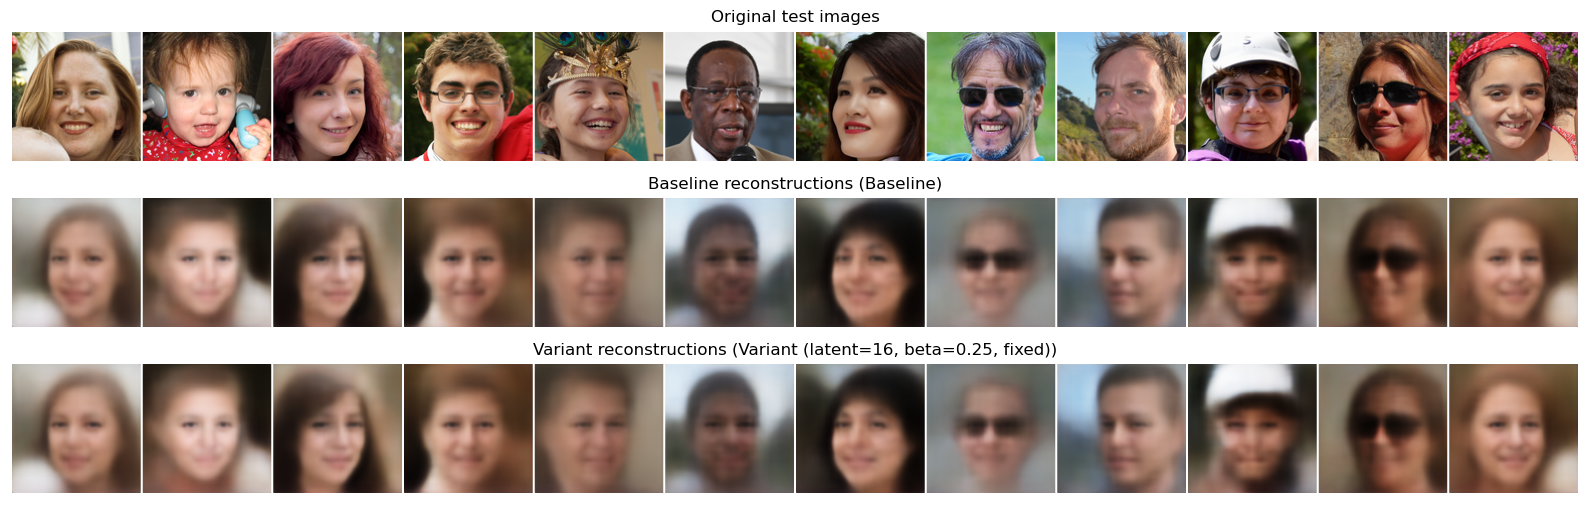

,image_id,floor,baseline excess,variant excess,variant - baseline
position,,,,,
1,64583,27035.000000,2880.100098,2844.699951,-35.400002
2,68748,24219.900391,3041.500000,2997.800049,-43.700001
3,63414,26953.199219,1656.500000,1695.099976,38.599998
4,63543,24547.099609,2971.300049,2875.300049,-96.000000
5,61595,29576.199219,2159.600098,2111.800049,-47.799999
6,63067,25023.900391,3001.699951,2935.399902,-66.199997
7,64252,22314.599609,2496.199951,2399.199951,-97.000000
8,66727,30329.699219,2491.699951,2505.100098,13.400000
9,66417,29264.500000,2057.500000,1949.099976,-108.300003


In [14]:
# Produce the required reconstruction comparison here.

gen = torch.Generator().manual_seed(GEN_SEED)
recon_indices = torch.randperm(len(datasets["test"]), generator=gen)[:NUM_RECON_IMAGES].tolist()
recon_images = torch.stack([datasets["test"][i][0] for i in recon_indices])
recon_image_ids = [datasets["test"][i][1] for i in recon_indices]
print("Test image_ids used:", recon_image_ids)

@torch.no_grad()
def reconstruct_mean(model, x):
    # Deterministic reconstruction from the posterior mean z = mu
    model.eval()
    mu, _ = model.encode(x.to(DEVICE))
    return torch.sigmoid(model.decode(mu)).cpu()

recons = {label: reconstruct_mean(model, recon_images) for label, model, _ in MODELS}

fig, axes = plt.subplots(3, 1, figsize=(16, 5.2))
show_grid(recon_images, NUM_RECON_IMAGES, "Original test images", axes[0])
show_grid(recons["Baseline"], NUM_RECON_IMAGES, f"Baseline reconstructions ({BASELINE_CONFIG['name']})", axes[1])
show_grid(recons["Variant"], NUM_RECON_IMAGES, f"Variant reconstructions ({VARIANT_CONFIG['name']})", axes[2])
plt.tight_layout(); plt.show()

# Per-image reconstruction loss for these 12 images (supports failure-case analysis)
with torch.no_grad():
    per_img = {}
    for label, model, _ in MODELS:
        model.eval()
        mu, _ = model.encode(recon_images.to(DEVICE))
        per_img[label]=reconstruction_loss(model.decode(mu), recon_images.to(DEVICE)).cpu().numpy()

# Raw BCE includes each image's own floor (busy, high-entropy images have a high floor even when 
# reconstructed well), so failure cases are identified by the excess over that floor.

floor_12 = reconstruction_floor(recon_images).numpy()
per_img_table = pd.DataFrame(
{
    "position": range(1, NUM_RECON_IMAGES+1),
    "image_id": recon_image_ids,
    "floor": floor_12,
    "baseline excess": per_img["Baseline"]-floor_12,
    "variant excess": per_img["Variant"]-floor_12
})
per_img_table["variant - baseline"] = per_img_table["variant excess"] - per_img_table["baseline excess"]
display(per_img_table.set_index("position").round(1))
        

### 5.3 Prior samples

Show at least 64 samples from each model in an 8 by 8 grid, using the same
generation seed.


*Method:* both models have `latent_dim = 16`, so the same 64 vectors `z ~ N(0, I)` drawn with `GEN_SEED = 2026` are decoded by each model; grid cell (row r, column c) holds the same `z` in both grids.

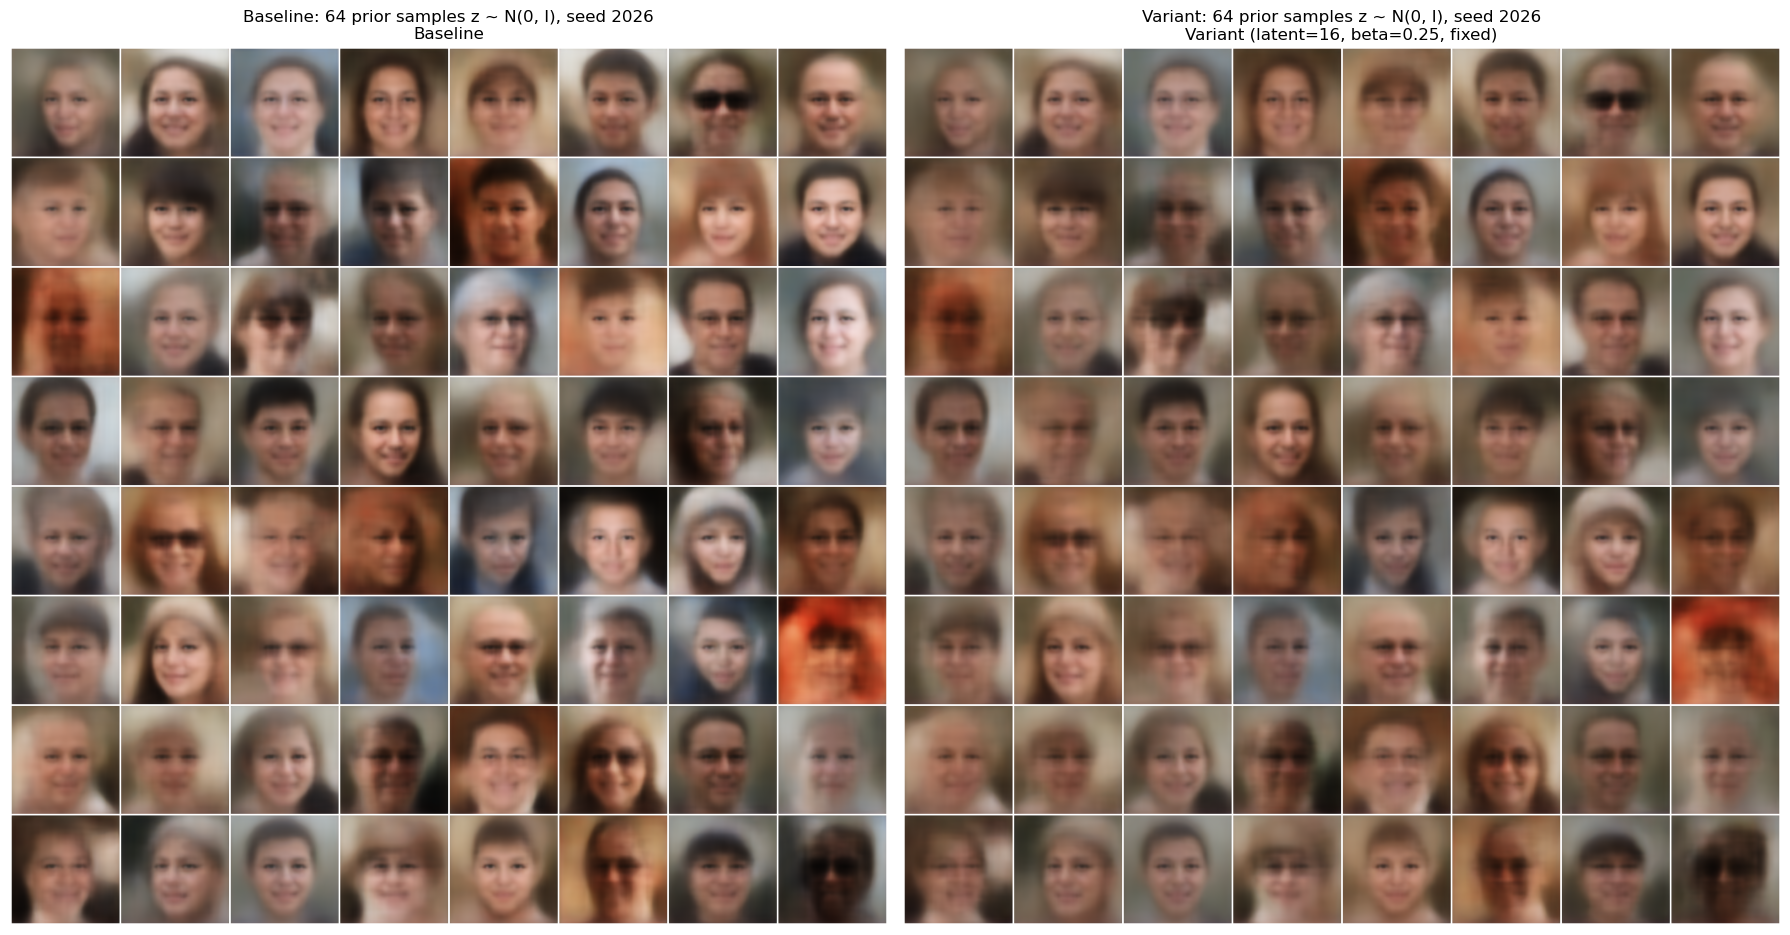

In [15]:
# Produce the baseline and variant prior-sample grids here.
@torch.no_grad()
def prior_samples(model, n, seed):
    model.eval()
    g = torch.Generator().manual_seed(seed) # same generation seed for both models
    z = torch.randn(n, model.latent_dim, generator=g).to(DEVICE)
    return torch.sigmoid(model.decode(z)).cpu()

fig, axes = plt.subplots(1, 2, figsize=(18, 9.5))
for ax, (label, model, cfg) in zip(axes, MODELS):
    show_grid(prior_samples(model, NUM_PRIOR_SAMPLES, GEN_SEED), 8,
              f"{label}: {NUM_PRIOR_SAMPLES} prior samples z ~ N(0, I), seed {GEN_SEED}\n{cfg['name']}", ax)
plt.tight_layout(); plt.show()

### 5.4 Latent interpolation

Use at least 12 interpolation steps between the same two encoded test images
for both models.


*Method:* endpoints are positions 1 and 2 of the reconstruction set in 5.2, encoded to their posterior means. Each row shows original A, the 12 interpolation steps (decoded frames at alpha = 0, 1/11, ..., 1 along the straight line between the two means), then original B.

Interpolation endpoint image_ids: [64583, 68748]


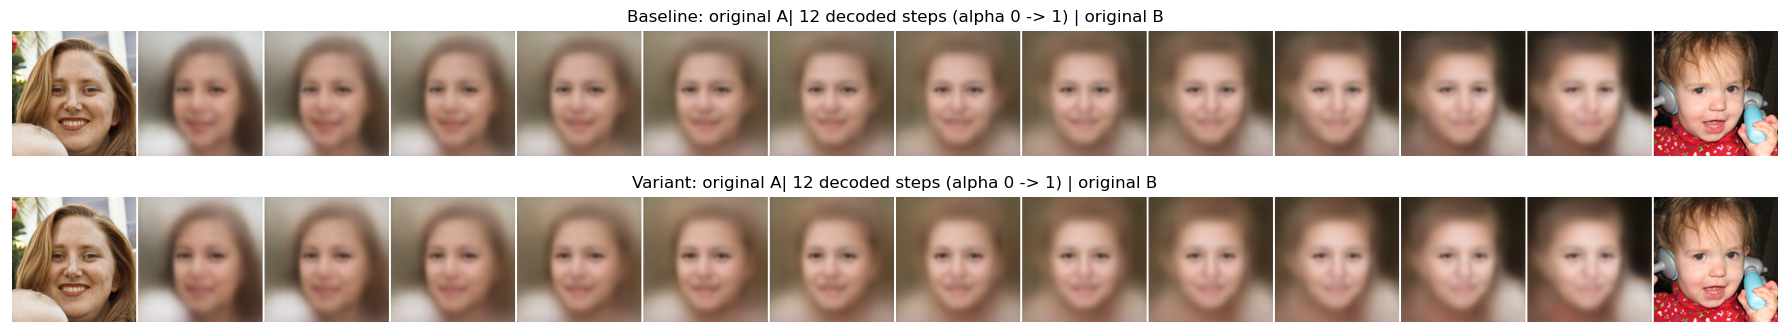

In [16]:
# Produce both latent interpolations here.

interp_endpoints = recon_images[:2]
print("Interpolation endpoint image_ids:", recon_image_ids[:2])

@torch.no_grad()
def interpolate(model, x_pair, steps):
    model.eval()
    mu, _ = model.encode(x_pair.to(DEVICE))
    alphas = torch.linspace(0.0, 1.0, steps, device=DEVICE).unsqueeze(1)
    z = (1-alphas)*mu[0:1]+alphas*mu[1:2] #linear path between posterior means
    return torch.sigmoid(model.decode(z)).cpu()

fig, axes = plt.subplots(2, 1, figsize=(18, 3.6))
for ax, (label, model, cfg) in zip(axes, MODELS):
    path = interpolate(model, interp_endpoints, NUM_INTERP_STEPS)
    row = torch.cat([interp_endpoints[0:1], path, interp_endpoints[1:2]])
    show_grid(row, len(row), f"{label}: original A| {NUM_INTERP_STEPS} decoded steps (alpha 0 -> 1) | original B", ax)
plt.tight_layout(); plt.show()

### 5.5 Training and validation curves

Plot total, reconstruction, and unweighted KL for train and validation for both
models. Labels must distinguish model, split, and loss component.


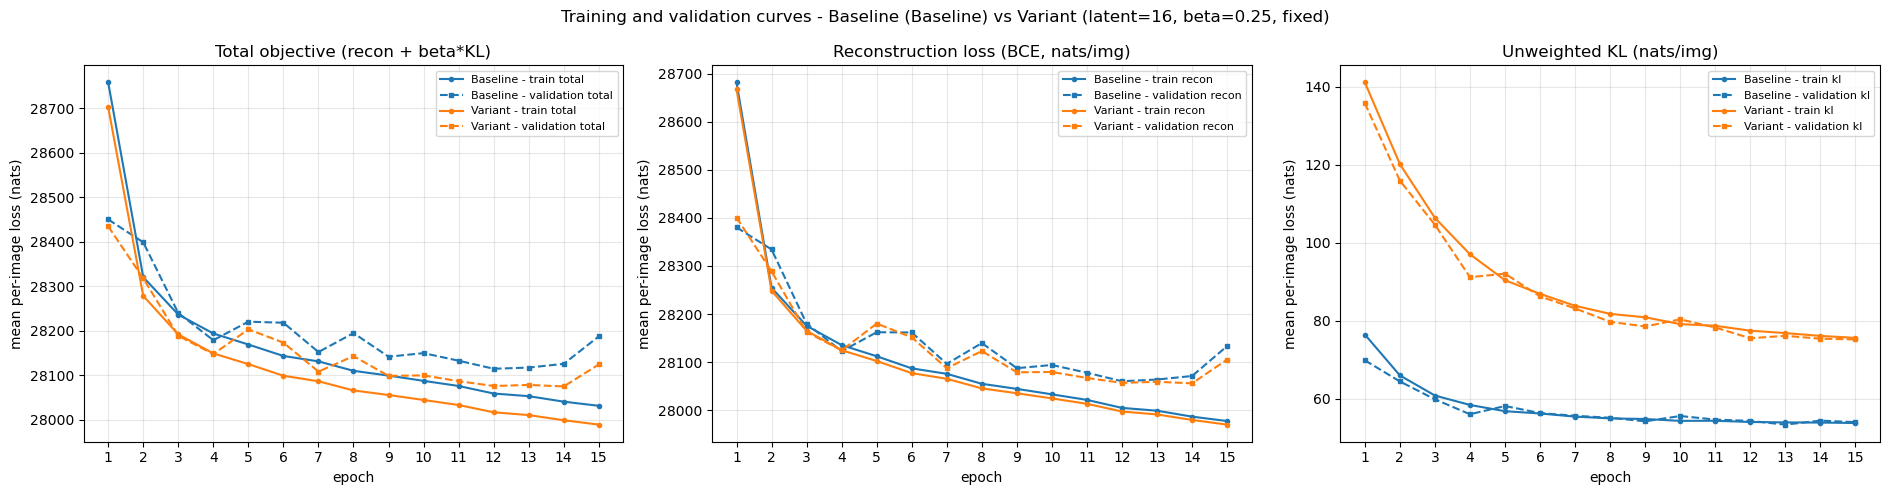

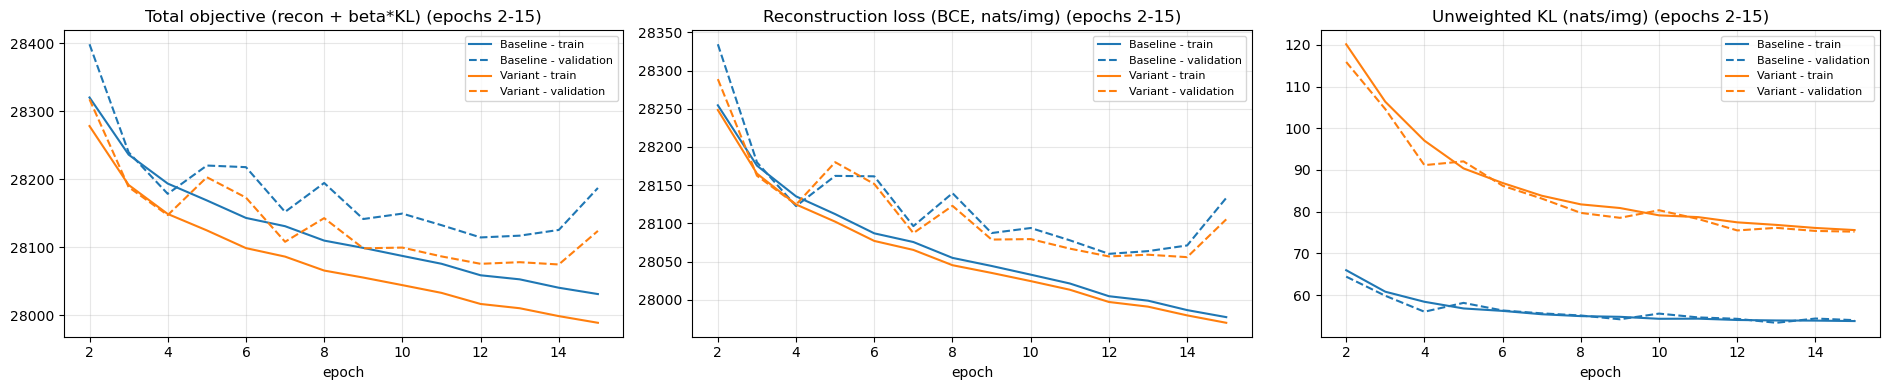

In [17]:
# Produce the required comparison curves here.

components = [
    ("total", "Total objective (recon + beta*KL)"),
    ("recon", "Reconstruction loss (BCE, nats/img)"),
    ("kl", "Unweighted KL (nats/img)")
]
styles = {"Baseline": "tab:blue", "Variant": "tab:orange"}
histories = {"Baseline": baseline_history, "Variant": variant_history}

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (comp, title) in zip(axes, components):
    for label, hist in histories.items():
        ax.plot(hist.index, hist[f"train_{comp}"], color=styles[label], linestyle="-", marker="o",
                markersize=3, label=f"{label} - train {comp}")
        ax.plot(hist.index, hist[f"val_{comp}"], color=styles[label], linestyle="--", marker="s",
                markersize=3, label=f"{label} - validation {comp}")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.set_ylabel("mean per-image loss (nats)")
    ax.set_xticks(range(1, EPOCHS + 1))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle(f"Training and validation curves - Baseline ({BASELINE_CONFIG['name']}) vs {VARIANT_CONFIG['name']}")
plt.tight_layout()
plt.show()

# Zoomed view of epochs 2-15 (epoch 1 dominates the y-axis scale)
fig, axes = plt.subplots(1, 3, figsize=(19, 4))
for ax, (comp, title) in zip(axes, components):
    for label, hist in histories.items():
        h=hist.loc[2:]
        ax.plot(h.index, h[f"train_{comp}"], color=styles[label], linestyle="-", label=f"{label} - train")
        ax.plot(h.index, h[f"val_{comp}"], color=styles[label], linestyle="--", label=f"{label} - validation")
    ax.set_title(title+" (epochs 2-15)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.6 Evidence summary for the report

This cell prints the exact values referenced in Sections B and C, so every number in the report can be traced to an executed output.

In [18]:
b, v = test_table.loc["Baseline"], test_table.loc["Variant"]

def pct(new, old):
    return 100.0 * (new-old)/abs(old) if old else np.nan

summary = pd.DataFrame({
    "Baseline": [
        b["test recon (nats/img)"], 
        b["test KL unweighted (nats/img)"],
        b["test total = recon + beta*KL"],
        b["neg. ELBO at beta=1 (recon + KL)"],
        b["active units (Var[mu_j] > 0.01)"],
        baseline_history["val_recon"].iloc[-1],
        baseline_history["val_kl"].iloc[-1],
        baseline_history["val_total"].idxmin(),
        baseline_history["train_recon"].iloc[-1] - baseline_history["val_recon"].iloc[-1]
    ],
    "Variant": [
        v["test recon (nats/img)"], 
        v["test KL unweighted (nats/img)"], 
        v["test total = recon + beta*KL"],
        v["neg. ELBO at beta=1 (recon + KL)"], 
        v["active units (Var[mu_j] > 0.01)"],
        variant_history["val_recon"].iloc[-1],
        variant_history["val_kl"].iloc[-1],
        variant_history["val_total"].idxmin(), 
        variant_history["train_recon"].iloc[-1] - variant_history["val_recon"].iloc[-1]
    ],
}, index= ["test recon", 
           "test KL", 
           "test total (own beta)", 
           "test neg. ELBO (beta=1)", 
           "active units (of 16)",
           "val recon @ epoch 15",
           "val KL @ epoch 15", 
           "epoch of min val total", 
           "train - val recon @ epoch 15"])
summary["variant vs baseline (%)"] = [
    pct(summary.loc[r, "Variant"], summary.loc[r, "Baseline"])
    if r not in ("epoch of min val total", "train - val recon @ epoch 15") else np.nan
    for r in summary.index]

display(summary.round(3))


,Baseline,Variant,variant vs baseline (%)
test recon,28066.211,28039.441,-0.095
test KL,54.240,75.634,39.442
test total (own beta),28120.452,28058.350,-0.221
test neg. ELBO (beta=1),28120.452,28115.075,-0.019
active units (of 16),16.000,16.000,0.000
val recon @ epoch 15,28133.239,28105.219,-0.100
val KL @ epoch 15,54.011,75.218,39.263
epoch of min val total,12.000,14.000,NaN
train - val recon @ epoch 15,-156.040,-135.429,NaN


## 6. Notebook report

### A. Design rationale

Explain the architecture, reconstruction term, decoder output, optimiser,
learning rate, and stability choices. Tie each choice to FFHQ128 and your model.

**Response:**

*Architecture.* FFHQ128 faces are aligned, so identity-defining structure (eyes, nose, mouth) sits at nearly fixed positions and the main variation is pose, lighting, hair and background. A five-stage strided-convolution encoder (32 -> 64 -> 128 -> 256 -> 256 channels) halves resolution at every stage from `128 x 128` to `4 x 4`, so local texture is captured early and the `4 x 4 x 256` bottleneck summarises the whole face before two separate Linear heads produce `mu` and `logvar`. The decoder mirrors this with nearest-neighbour upsampling followed by a `3 x 3` convolution at each scale, which avoids the checkerboard artefacts transposed convolutions tend to produce on large smooth regions such as skin and blurred backgrounds. Every convolutional block uses BatchNorm and LeakyReLU(0.2). The model has 2,928,451 trainable parameters (Section 2), well inside the 10 M budget: with only 16 latent dimensions the bottleneck, not decoder capacity, limits detail, and a smaller model keeps `2 x 15` epochs on 30,000 images practical on a single GPU.

*Reconstruction term and decoder output.* The decoder outputs unbounded logits and the reconstruction term is `binary_cross_entropy_with_logits`, summed over all 49,152 pixel-channel values of an image. Pixels are supplied in [0, 1], so they are valid targets for a sigmoid-Bernoulli decoder, and fusing the sigmoid into the loss uses the log-sum-exp form, which avoids `log(0)` for saturated pixels. Summing per image (rather than averaging per pixel) puts reconstruction and KL on the same per-image scale, so `beta = 1` is the true negative ELBO; averaging per pixel would silently shrink the reconstruction weight by about 49,000x and push the model towards posterior collapse. I chose BCE over a fixed-variance Gaussian (MSE) because a fixed unit-variance Gaussian (MSE/2 summed per image) gives a comparatively weak reconstruction signal on [0, 1] data, which favours blurrier reconstructions and posterior collapse. The known limitation is that BCE on continuous targets is not a normalised density, so its minimum is not zero; I therefore interpret reconstruction values only comparatively.

*Optimiser and learning rate.* Adam with `lr = 1e-3 (β₁ = 0.9, β₂ = 0.999)`, batch size 64, constant rate, identical for both runs. Adam's per-parameter normalisation handles the large gradient magnitudes produced by the summed loss, and 1e-3 allows meaningful convergence within the fixed 15-epoch budget (7,035 updates).

*Stability measures.* (i) `logvar` is clamped to [-10, 10] so `exp(logvar)` cannot overflow or underflow in the reparameterisation and KL; (ii) logits plus BCE-with-logits for numerically stable reconstruction; (iii) BatchNorm in every convolutional block; (iv) a non-finite-loss guard that stops training immediately, and per-epoch maximum gradient norms logged as a diagnostic; (v) evaluation with a forked, fixed RNG so validation and test numbers are repeatable and do not change the training random stream; (vi) the seed is reset and the loaders recreated before each run, verified by identical first-batch image IDs and initial-weight checksums.


*Observed behaviour supporting these choices.* Before training, the summed per-image BCE (34,760.10 nats) was four orders of magnitude larger than the KL (2.16 nats; §3 checks). The training KL nevertheless settled at 53.79 nats per image by epoch 15 (§4.1; about 3.4 nats per latent dimension), and all 16 units are active on the test set (§5.1), so the per-image summed reduction did not cause posterior collapse. No loss became non-finite in either run (7,035 steps each). The largest gradient norm fell from 24,924 in epoch 1 to 3,602 in epoch 15 for the baseline (24,620 to 3,695 for the variant) without clipping, which indicates that Adam with `lr = 1e-3` was stable for this model. Validation loss stopped improving after epoch 12 (baseline) and 14 (variant) while training loss kept falling, so a longer schedule alone would not obviously have improved validation loss.

### B. Controlled comparison

Evaluate your prediction using at least three exact own-run values and at least
three specific figure observations. Explain the reconstruction-KL trade-off and
identify at least one visible failure case.

**Response:**

*Prediction (stated in §4.2 before training):* lowering β from 1.0 to 0.25 would (i) lower reconstruction loss and give visibly sharper reconstructions, (ii) raise the unweighted KL and the number of active units, (iii) produce worse prior samples, (iv) make interpolations less smooth, and (v) leave the `β = 1` negative ELBO similar or slightly worse.

**Quantitative evidence**
1. *Reconstruction improved slightly but consistently.* Test reconstruction was 28,066.21 (baseline) vs 28,039.44 (variant) nats/image; relative to the 25,322.17-nat floor, the excess error fell from 2,744.04 to 2,717.27 (-1.0%). Because both runs share initial weights, data order and evaluation noise, the curves compare epoch by epoch: the variant's validation reconstruction is lower at every epoch from 6 to 15 (by 3.4-28.0 nats) and its training reconstruction at all 15 epochs (by 6.2-14.4). The gain is systematic within this seed; whether it holds across seeds is untested.
2. *KL increased substantially.* Test unweighted KL rose from 54.24 to 75.63 nats/image (+39.4%; validation at epoch 15: 54.01 -> 75.22), and Var[mu_j] increased in all 16 dimensions (1.37-2.39 -> 2.62-4.75). Both models have 16/16 active units, so the "more active units" part of (ii) could not be tested.
3. *The `β = 1` negative ELBO is effectively unchanged:* 28,120.45 vs 28,115.08 nats/image (-5.4 nats, 0.02%), consistent with (v). This is far smaller than the 35-62-nat validation spikes at epochs 5, 8 and 15 (§5.5), so I treat the models as tied. Test totals at each model's own β (28,120.45 vs 28,058.35) are not compared, because the models optimise different objectives.
4. *KL dynamics (§5.5).* Neither KL collapsed or recovered: training KL declines steadily in both runs and validation KL fluctuates by at most 2.1 nats. The training-KL gap narrowed from 64.6 nats (epoch 1) to 21.8 (epoch 15), and the variant's KL was still falling by about 0.5 nats per epoch (baseline 0.1), so the +39% depends partly on the 15-epoch budget.

**Visual evidence**
1. *Reconstructions (§5.2).* The baseline and variant rows are nearly indistinguishable, so the 1% gain is not perceptible and "visibly sharper" in (i) is not supported. Both models keep the global layout (head position, hair outline, background brightness) and dark sunglasses (positions 8, 11), but lose clear-lens glasses (4, 6, 10), the feathered headdress (5), the handheld device and red clothing (2) and the red headscarf (12), and render the red hair at position 3 as brown: only high-contrast structure reaches the 16-dimensional code.
2. *Prior samples (§5.3; cell (r, c) uses the same z in both grids).* The variant's samples are lower in contrast, less detailed and more alike (e.g. row 1 col 2, row 2 col 1). Row 3 col 1 and row 6 col 8 fail in both models as orange-red smears without clear facial structure. This supports (iii), but through averaging rather than the distortion I predicted.
3. *Interpolation (§5.4).* Both paths are smooth, every frame is face-like and the two rows are very similar, so (iv) is not supported. Endpoint B's device and red clothing never appear along either path, because they were already lost at encoding (position 2, §5.2).

**Interpretation of the reconstruction-regularisation trade-off.** Lowering β let the encoder store more information (KL +21.4 nats, Var[mu_j] roughly doubled) but bought only 26.8 nats of reconstruction, leaving the `β = 1` objective unchanged. The extra information mainly spread the codes apart rather than capturing new detail (the accessories lost by the baseline are still lost), which suggests reconstruction is limited by the 16-dimensional bottleneck, the decoder and the factorised BCE likelihood rather than by the KL weight. The cost appears in generation: because Var[mu_j] exceeds the prior's variance of 1 in both models, `z ~ N(0, I)` covers only the central part of the region the encoder uses (at most about 0.75 posterior-mean standard deviations for the baseline and 0.53 for the variant, 1/√mean Var[mu_j]; the posterior variances σ² widen the region further). The variant's prior samples therefore fall nearer its average face, matching its lower-contrast, more uniform grid. In summary: (ii) KL and (v) ELBO were confirmed, (i) in direction only (small and invisible), (iii) through averaging rather than distortion, and (iv) was not supported.

**Failure case.** Position 10 (image_id 66862) has the largest excess reconstruction error in both models (5,788.4 and 5,638.3 nats; 1.9x the next-highest image). A white helmet covers the top of the head, with glasses and purple clothing; both models render the helmet as a uniform white blob, remove the glasses and average the facial features. Two causes combine: a rare accessory fills much of the frame and cannot be represented by the 16-dimensional code, and the image has the lowest floor of the twelve (20,003.8 nats, i.e. large near-white regions), where BCE penalises errors heavily (0.118 nats per pixel value vs a test mean of 0.056). The variant reduces this error by only 150.1 nats, so lowering β does not fix it.

### C. Limitations and next experiment

Identify limitations visible in your results. Propose one technically specific,
testable next experiment and state what outcome would support it.

**Response:**

**Limitations visible in the results**
1. *Loss of fine and rare detail (§5.2).* Both models reconstruct blurred, averaged faces: clear-lens glasses, headwear, hand-held objects and coloured clothing are removed (positions 2, 4, 5, 6, 10, 12), and only high-contrast features such as dark sunglasses survive (8, 11).
2. *BCE weights errors unevenly.* Position 10 has the lowest floor and twice the mean per-pixel excess error (0.118 vs 0.056 nats), so the per-image loss partly reflects how BCE treats near-saturated pixels rather than how visible the error is.
3. *Checkpoint selection.* The test results use the epoch-15 weights, but validation total was lowest at epoch 12 (baseline, 28,114.39) and epoch 14 (variant, 28,074.59); epoch 15 is a validation spike in both runs (+61.8 and +49.4 nats). Evaluating both models at the same epoch keeps the comparison fair, but the absolute test values are pessimistic.
4. *Plateau and a widening generalisation gap.* Training loss was still falling by 9-10 nats per epoch at epoch 15, but from epoch 9 to 14 the baseline's validation reconstruction fell only 16 nats against 58 for training. The validation-minus-training reconstruction gap fluctuated between -13 and 85 nats over epochs 3-14 and reached 156 nats at the epoch-15 spike (about 6% of the excess error), so more epochs alone may widen this gap rather than improve validation loss.
5. *Single seed and shared artefacts.* The validation spikes fall at the same epochs (5, 8, 15) in both runs, which points to the shared data order (the last mini-batches and BatchNorm running statistics) rather than random noise, and with one seed per condition the cross-seed variability of the 26.8-nat reconstruction difference is unknown. BCE on continuous targets is not a normalised likelihood, and sample quality was judged by eye, without a metric such as FID.

**Next experiment.** Replace the Bernoulli/BCE decoder with a Gaussian decoder whose shared log-variance is learned jointly with the network (σ-VAE; Rybkin et al., 2021). Keep latent_dim = 16, β = 1, the architecture, seed, data order, optimiser, learning rate and 15 epochs unchanged, and evaluate both models at their best-validation epoch. The learned variance calibrates the reconstruction-KL balance from the data and weights all pixel values equally rather than up-weighting near-saturated ones (limitation 2). Because the two losses are on different scales, the models are compared on shared measures. The proposal is supported if, against this baseline: (a) the mean per-image test MSE is lower; (b) the mean Laplacian variance of the 12 §5.2 reconstructions is higher (sharper), and positions 4, 6, and 10 retain their glasses; (c) the per-image contrast (pixel standard deviation) of the 64 prior samples is closer to that of the test images; and (d) the KL stays clearly above zero. If the KL collapses or the samples degrade, the proposal is not supported.

## 7. References, sources, and AI-use declaration

This section is mandatory. Add one row for every external source or AI tool.
Identify exact affected cells, functions, figures, or report sections. Explain
what was retained or adapted and how you independently verified it.


| Source/tool and version | Purpose | Exact affected cells/functions/sections | Material retained or adapted | Independent verification |
|---|---|---|---|---|
| 1 - Claude Code (Anthropic), Claude Opus 5.5 | Understand some methods and usages like `torch.cat`, `torch.Generator()`, gpu and mps differentiation in execution | some methods, keywords used in cell 1, cell 4, cell 10 | just used to understand the concepts | wrote own code and verified after execution |
| 2 - Claude Code (Anthropic), Claude Opus 5.5 | fine tune wordings in descriptions | Notebook report section | some of the fine tuned wordings in report section | went through the content again and verified the idea |
| 3 - PyTorch documentation | API semantics| `binary_cross_entropy_with_logits`, `torch.random.fork_rng`, `clip_grad_norm_`, in cell 7, cell 10 | API usage | §3 checks |
| 4 - FFHQ dataset, official NVIDIA release(Karras et al., 2019) `thumbnails128x128` | Training and evaluation data | All data cells | images used unmodified, course manifest subset only | Split size, disjointness, file presence and value range checked |


**Generative AI declaration:** Used 

**External code or tutorial declaration:** Used  

References:
- Burda, Y., Grosse, R., & Salakhutdinov, R. (2016). Importance weighted autoencoders. *International Conference on Learning Representations (ICLR)*. (Active-unit measure, Section 5.1.)
- Karras, T., Laine, S., & Aila, T. (2019). A style-based generator architecture for generative adversarial networks. *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*, 4401–4410. (FFHQ dataset, Section 1.)
- Kingma, D. P., & Welling, M. (2014). Auto-encoding variational Bayes. *International Conference on Learning Representations (ICLR)*. arXiv:1312.6114. (Reparameterisation; analytic Gaussian KL, Appendix B.)
- Rybkin, O., Daniilidis, K., & Levine, S. (2021). Simple and effective VAE training with calibrated decoders. *Proceedings of the 38th International Conference on Machine Learning (ICML)*, PMLR 139. (σ-VAE, next experiment in C.)

## Final submission check

- [x] Baseline and one variant each have 15 visible epochs.
- [x] Train/validation total, reconstruction, and unweighted KL are visible.
- [x] Test result table and all required figures are visible.
- [x] Numerical and figure-specific report claims match notebook evidence.
- [x] Source and AI-use declaration is complete and specific.
- [x] Kernel restart and Run All completes without unresolved errors.
